# P12 · Mobile-Money Fraud Miner — Mining Lead Notebook (Week 8)

**Course:** DS-311 Data Mining · BS-AI 2024F, Section A · NBC, NUST · Fall 2026  
**Author:** Shoaib Malik (Team Leader, Mining lead) · **Group 2:** Shoaib Malik, Uzair Kakar, Salman Hussian  
**Week / milestone:** Week 8 (M2), first model

**What this notebook needs:** `paysim_transfer_cashout.parquet` in Drive `processed/`, `src/features.py` from Uzair's branch (`uzair/week8-features-leakage`), and `src/pipeline.py` and `src/metrics.py` from my branch (`shoaib/week8-split-baselines`).

**Goal:** build an *honest* evaluation set-up (time-based split, sampling only on training data, a leakage-safe Pipeline) and produce the first baseline results table (dummy vs decision tree) with **PR-AUC**, never accuracy.

---
### How to read this notebook (for the instructor)
Every section follows the same pattern as notebook 01:

| Label | Meaning |
|---|---|
| **Purpose** | Which project question or pipeline stage this section serves |
| **What we did** | The steps, in plain words |
| **How to read the output** | What the table or chart under the code shows |
| **Finding** | A line printed by the code itself with the real numbers (nothing typed by hand) |

### Notebook map

| Section | Pipeline stage (course guide) | Question it answers |
|---|---|---|
| 1. Setup | Reproducibility | Are seeds and library versions fixed and recorded? |
| 2. Repo modules and data | Team workflow, Stage 1 | Do the shared `src/` modules and the processed file load? |
| 3. Features | Stage 4: Transform | Do Uzair's engineered columns connect to my code without NaN or infinity? |
| 4. Time split and sampling | Stage 5: Evaluation design | How do we split and sample so the test result is honest? |
| 5. Pipeline | Stage 5: Model set-up | Is every preprocessing step fitted on training data only? |
| 6. Baselines | Stage 6: Modelling | What does a model that knows nothing score, and how good is a tuned tree? |
| 7. Results and curves | Stage 7: Evaluation | How do dummy and tree compare on the natural test set? |
| 8. Sampling demo | Stage 7: Evaluation ("watch out") | How much does testing on sampled data inflate the metrics? |
| 9. Save outputs | Team workflow | What do Salman's app page and the final demo receive? |
| 10. Summary | Interpretation | What did we learn, what are the limits, what comes next? |

**How to run:** `Runtime > Restart session and run all`. The data cell asks for Google Drive access (click Allow). The test set is used **only** in sections 7 and 8.

## 1. Setup

**Purpose:** make the notebook reproducible (a course requirement): the same code gives the same results for anyone who runs it.

**What we did:** imported the libraries, fixed the random seed (`SEED = 42`), set display options, and printed the library versions. The `scikit-learn` version printed here is the one we **pin in `requirements.txt`**, so the saved model loads on Streamlit Cloud.

**How to read the output:** one line of versions, then the two lines to copy into `requirements.txt`. No errors are expected.

In [1]:
import os, sys, json, warnings, importlib, subprocess, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn, joblib
from sklearn import set_config
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_curve

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| joblib", joblib.__version__)
print("Seed:", SEED)
print("=" * 70)
print("Lines to put in requirements.txt (pinned versions):")
print(f"scikit-learn=={sklearn.__version__}")
print(f"joblib=={joblib.__version__}")

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | scipy 1.16.3 | scikit-learn 1.6.1 | joblib 1.6.0
Seed: 42
Lines to put in requirements.txt (pinned versions):
scikit-learn==1.6.1
joblib==1.6.0


## 2. Repo modules and data

### 2.1 Get the shared modules from the repository

**Purpose:** notebooks do not copy code from each other. Shared code lives in `src/` and is imported (notebook rule 3). Uzair's `features.py` is not merged yet, so we take it from his branch; our own two modules come from our branch.

**What we did:**
- cloned the repository into a folder called `repo`;
- fetched `src/features.py` from Uzair's branch and `src/pipeline.py` and `src/metrics.py` from our own branch (the same `fetch` and `checkout FETCH_HEAD` method as in the team handout);
- added `repo` to `sys.path` and imported the three modules.

**After Wednesday's merge:** set the two `USE_MAIN_...` switches to `True`; the files are then taken from `main`.

**How to read the output:** the listing of `repo/src` should show `features.py`, `pipeline.py` and `metrics.py`. If the clone fails, the repository is private or a branch name is wrong. No password or token may be typed into a cell.

In [2]:
REPO_URL      = "https://github.com/shoaibmalik2006/ds311-p12-mobile-money-fraud-miner.git"
UZAIR_BRANCH  = "uzair/week8-features-leakage"
SHOAIB_BRANCH = "shoaib/week8-split-baselines"
USE_MAIN_FOR_FEATURES   = False   # set True after Uzair's PR is merged
USE_MAIN_FOR_MY_MODULES = False   # set True after my PR is merged

def run(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out)
    if r.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}")

run("rm -rf repo")
run(f"git clone -q {REPO_URL} repo")
if not USE_MAIN_FOR_FEATURES:
    run(f"git -C repo fetch -q origin {UZAIR_BRANCH}")
    run("git -C repo checkout FETCH_HEAD -- src/features.py")
if not USE_MAIN_FOR_MY_MODULES:
    run(f"git -C repo fetch -q origin {SHOAIB_BRANCH}")
    run("git -C repo checkout FETCH_HEAD -- src/pipeline.py src/metrics.py")

if "repo" not in sys.path:
    sys.path.insert(0, "repo")
from src import features, pipeline, metrics
for m in (features, pipeline, metrics):
    importlib.reload(m)

print("Files in repo/src:", sorted(os.listdir("repo/src")))
print("Imports OK:", features.__name__, pipeline.__name__, metrics.__name__)

Files in repo/src: ['__init__.py', '__pycache__', 'features.py', 'metrics.py', 'pipeline.py']
Imports OK: src.features src.pipeline src.metrics


### 2.2 Load the processed data

**Purpose:** read the file saved at the end of notebook 01 (Stage 1 of the pipeline). It holds only the TRANSFER and CASH_OUT rows, because all frauds live in those two types.

**What we did:** mounted Google Drive and read `paysim_transfer_cashout.parquet` from `DS311_P12_Data/processed/` (fallback: the `.csv.gz` version). We then checked that the columns we need are present and printed the size, the number of frauds and the step range.

**How to read the output:** expect about 2.77 million rows and 8,213 frauds (about 0.30 %), with `step` from 1 to 743. If `step` is missing, rerun the Save cell of notebook 01.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive/DS311_P12_Data"
PROC_DIR   = DRIVE_ROOT + "/processed"
parquet_path = PROC_DIR + "/paysim_transfer_cashout.parquet"
csv_path     = PROC_DIR + "/paysim_transfer_cashout.csv.gz"

if os.path.exists(parquet_path):
    df = pd.read_parquet(parquet_path); DATA_FILE = parquet_path
elif os.path.exists(csv_path):
    df = pd.read_csv(csv_path); DATA_FILE = csv_path
else:
    raise FileNotFoundError("Processed file not found. Run notebook 01 (Save cell) first.")

required = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}. Rerun the Save cell of notebook 01."

print("Loaded:", DATA_FILE)
print("Shape (rows, columns):", df.shape)
print("Types present:", sorted(df["type"].astype(str).unique()))
print(f"Finding: {len(df):,} rows, {int(df['isFraud'].sum()):,} frauds = {df['isFraud'].mean():.3%}; "
      f"step runs from {int(df['step'].min())} to {int(df['step'].max())}.")

Mounted at /content/drive
Loaded: /content/drive/MyDrive/DS311_P12_Data/processed/paysim_transfer_cashout.parquet
Shape (rows, columns): (2770409, 13)
Types present: ['CASH_OUT', 'TRANSFER']
Finding: 2,770,409 rows, 8,213 frauds = 0.296%; step runs from 1 to 743.


## 3. Add Uzair's features

**Purpose:** prove that the three members' modules connect (Stage 4: transform). The model inputs come from `src/features.py`, so everybody uses the same columns.

**What we did:**
- applied Uzair's feature function to the dataframe;
- printed the **new column names** it created;
- checked that the feature columns contain **no NaN and no infinite values**, and that flag columns contain only 0 or 1;
- showed the first rows.

**Names to confirm with Uzair:** the cell looks for the function and the two feature lists (`full` and `deployable`) under a few likely names. If it cannot find them, it prints the names that exist; then edit the candidate lists in the first lines of the cell. We use the **full** list in Week 8; the **deployable** list (no new-balance columns) is for the Week 13 ablation.

**How to read the output:** the engineered columns appear next to the original ones, and the checks print zeros.

In [4]:
def pick(module, names, what):
    for n in names:
        if hasattr(module, n):
            return getattr(module, n), n
    public = [n for n in dir(module) if not n.startswith("_")]
    raise AttributeError(f"No {what} found in src/features.py. Names that exist: {public}. "
                         f"Edit the candidate list in this cell.")

FUNC_NAMES = ["add_features", "engineer_features", "build_features", "make_features", "add_engineered_features"]
FULL_NAMES = ["FULL", "FULL_FEATURES", "full", "full_features", "FEATURES_FULL"]
DEPL_NAMES = ["DEPLOYABLE", "DEPLOYABLE_FEATURES", "deployable", "deployable_features", "FEATURES_DEPLOYABLE"]

feature_fn, fn_name = pick(features, FUNC_NAMES, "feature function")
FULL_FEATURES, full_name = pick(features, FULL_NAMES, "full feature list")
FULL_FEATURES = list(FULL_FEATURES)
try:
    DEPLOYABLE_FEATURES, _ = pick(features, DEPL_NAMES, "deployable feature list")
    DEPLOYABLE_FEATURES = list(DEPLOYABLE_FEATURES)
except AttributeError:
    DEPLOYABLE_FEATURES = None
print(f"Using features.{fn_name}(), features.{full_name} ({len(FULL_FEATURES)} columns)")

cols_before = set(df.columns)
tmp = df.copy()
res = feature_fn(tmp)
df = tmp if res is None else res
new_cols = [c for c in df.columns if c not in cols_before]
print("New columns created by the function:", new_cols)

if "type" not in FULL_FEATURES:
    FULL_FEATURES = ["type"] + FULL_FEATURES
    print("Note: 'type' added to the feature list (it is one-hot encoded in the Pipeline).")
missing = [c for c in FULL_FEATURES if c not in df.columns]
assert not missing, f"Feature columns missing from the dataframe: {missing}"

num_check = df[[c for c in FULL_FEATURES if c != "type"]]
n_nan = int(num_check.isna().sum().sum())
n_inf = int(np.isinf(num_check.to_numpy(dtype="float64")).sum())
flag_like = [c for c in num_check.columns if num_check[c].nunique() <= 2]
bad_flags = {c: sorted(num_check[c].unique().tolist()) for c in flag_like if not set(num_check[c].unique()) <= {0, 1}}
print(f"NaN values in features: {n_nan} | infinite values: {n_inf} | flag columns not strictly 0/1: {bad_flags if bad_flags else 'none'}")
assert n_nan == 0 and n_inf == 0, "Fix the feature function before continuing."

display(df[FULL_FEATURES + ["isFraud"]].head())
print(f"Finding: {len(FULL_FEATURES)} model inputs are ready, with no NaN or infinite values.")

Using features.add_features(), features.FULL_FEATURES (13 columns)
New columns created by the function: ['type_is_transfer', 'errorBalanceOrig', 'errorBalanceDest', 'origEmptied', 'destZeroBefore', 'origBalanceZero', 'amountToBalanceRatio']
Note: 'type' added to the feature list (it is one-hot encoded in the Pipeline).
NaN values in features: 0 | infinite values: 0 | flag columns not strictly 0/1: none


,type,amount,oldbalanceOrg,oldbalanceDest,type_is_transfer,hour,destZeroBefore,origBalanceZero,amountToBalanceRatio,newbalanceOrig,newbalanceDest,errorBalanceOrig,errorBalanceDest,origEmptied,isFraud
2,TRANSFER,181.0000,181.0000,0.0000,1,0,1,0,1.0000,0.0000,0.0000,0.0000,181.0000,1,1
3,CASH_OUT,181.0000,181.0000,"21,182.0000",0,0,0,0,1.0000,0.0000,0.0000,0.0000,"21,363.0000",1,1
15,CASH_OUT,"229,133.9400","15,325.0000","5,083.0000",0,0,0,0,14.9516,0.0000,"51,513.4400","213,808.9400","182,703.5000",1,0
19,TRANSFER,"215,310.3000",705.0000,"22,425.0000",1,0,0,0,100.0000,0.0000,0.0000,"214,605.3000","237,735.3000",1,0
24,TRANSFER,"311,685.8900","10,835.0000","6,267.0000",1,0,0,0,28.7666,0.0000,"2,719,172.8900","300,850.8900","-2,401,220.0000",1,0


Finding: 14 model inputs are ready, with no NaN or infinite values.


## 4. Time-based split and sampling

### 4.1 Split by time

**Purpose:** Stage 5 (evaluation design). A real fraud system learns from the past and judges the future. A **random split lets the model see the future**, which makes results look better than they will be in practice.

**What we did:** split by `step`: **train** up to 500, **validation** 501 to 600, **test** above 600 (function `pipeline.time_split`). No shuffling before the split. We printed one summary row per period: step range, rows, frauds and fraud rate.

**What to check:** each period needs enough frauds, and the fraud rates should be similar. If one period is nearly empty, move the cut-offs and write the final cut-offs and the reason in the markdown cell under the table.

**Mistake to avoid:** shuffling before splitting.

**How to read the output:** the `Finding` line states the minimum number of frauds and the largest ratio between fraud rates. The warning (a heuristic of our own: fewer than 300 frauds, or rates more than 3 times apart) tells you if the cut-offs need to move.

In [5]:
TRAIN_END, VAL_END = pipeline.TRAIN_END, pipeline.VAL_END
train, val, test = pipeline.time_split(df, TRAIN_END, VAL_END)
split_table = pipeline.split_summary(train, val, test)
display(split_table)

assert len(train) + len(val) + len(test) == len(df), "Rows lost in the split"
assert train["step"].max() < val["step"].min() and val["step"].max() < test["step"].min(), "Periods overlap"

min_frauds = int(split_table["frauds"].min())
rates = split_table["fraud_rate_%"]
ratio = float(rates.max() / max(rates.min(), 1e-9))
print(f"Finding: cut-offs are train <= {TRAIN_END}, validation {TRAIN_END + 1} to {VAL_END}, test > {VAL_END}; "
      f"minimum frauds in a period = {min_frauds:,}; highest/lowest fraud rate = {ratio:.2f}.")
if min_frauds < 300 or ratio > 3:
    print("WARNING: a period has too few frauds or the rates differ a lot. Move the cut-offs in src/pipeline.py and rerun.")
else:
    print("Check passed: every period has enough frauds and the rates are similar. Write these cut-offs and the reason in the markdown below.")

,period,step_min,step_max,rows,frauds,fraud_rate_%
0,train,1,500,2645779,5561,0.2102
1,validation,501,600,81080,1052,1.2975
2,test,601,743,43550,1600,3.6739


Finding: cut-offs are train <= 500, validation 501 to 600, test > 600; minimum frauds in a period = 1,052; highest/lowest fraud rate = 17.48.


**Final cut-offs and reason (fill in after reading the table above):**  
Train: `step <= 500` · Validation: `501 to 600` · Test: `step > 600`.  
*Reason:* time order mimics a real system (learn from the past, judge the future). *(Write here whether the fraud counts and rates were acceptable, or which cut-off you moved and why.)*

### 4.2 Sample the training set

**Purpose:** fraud is about 0.3 % of this subset, so a model sees very few examples of the class we care about. Sampling the *training* set makes fraud easier to learn.

**What we did:** kept **all frauds plus 10 % of the normal rows** (seed 42) in the **training set only** (function `pipeline.sample_training`). Validation and test were not touched. We printed a before/after table of rows and fraud rate.

**Why validation and test keep the natural rate:** the real system will see about 0.3 % fraud, so the metrics must be measured at that rate to stay honest. Sampling also **changes the model's predicted probabilities** (they become too high); this is why *calibration* comes later (Week 12). Until then the 0.5 threshold is not calibrated.

**How to read the output:** the training fraud rate jumps from about 0.3 % to a few percent; the number of frauds stays the same.

In [6]:
train_s = pipeline.sample_training(train, frac_normal=0.10, seed=SEED)

sampling_table = pd.DataFrame({
    "rows": [len(train), len(train_s)],
    "frauds": [int(train["isFraud"].sum()), int(train_s["isFraud"].sum())],
    "fraud_rate_%": [100 * train["isFraud"].mean(), 100 * train_s["isFraud"].mean()],
}, index=["training set, natural", "training set, sampled"])
display(sampling_table)

assert int(train_s["isFraud"].sum()) == int(train["isFraud"].sum()), "A fraud was lost by the sampling"
print(f"Finding: the training fraud rate rose from {sampling_table.iloc[0, 2]:.2f}% to {sampling_table.iloc[1, 2]:.2f}% "
      f"with all {int(train_s['isFraud'].sum()):,} frauds kept; validation ({len(val):,} rows) and test ({len(test):,} rows) are unchanged.")

,rows,frauds,fraud_rate_%
"training set, natural",2645779,5561,0.2102
"training set, sampled",269583,5561,2.0628


Finding: the training fraud rate rose from 0.21% to 2.06% with all 5,561 frauds kept; validation (81,080 rows) and test (43,550 rows) are unchanged.


## 5. Build the Pipeline

**Purpose:** Stage 5 (model set-up). All preprocessing is placed *inside* one scikit-learn `Pipeline`, so every step is fitted on **training data only**. This prevents leakage: the validation and test sets never influence the encoders or scalers.

**What we did:**
- built `X` (the full feature set) and `y` for the sampled training set, the validation set and the test set;
- split the feature list into three groups: **`type`** (one-hot encoded), **numeric columns** (scaled with `StandardScaler`) and **0/1 flags** (passed through unchanged);
- assembled the Pipeline: `ColumnTransformer` (encoding, scaling, flags) followed by the model slot;
- displayed the Pipeline diagram.

**Why scale if trees do not need it:** a decision tree is not affected by scaling, but we keep the *same* Pipeline for later models (logistic regression, PCA, boosting), where scaling matters.

**How to read the output:** the three column groups, the shapes of X and y, and the diagram with its three blocks (`cat`, `num`, `flags`) followed by `model`.

In [7]:
CAT_COLS = ["type"]
rest = [c for c in FULL_FEATURES if c not in CAT_COLS]
FLAG_COLS = [c for c in rest if set(df[c].dropna().unique()) <= {0, 1}]
NUM_COLS  = [c for c in rest if c not in FLAG_COLS]
print("Categorical (one-hot):", CAT_COLS)
print("Numeric (scaled):     ", NUM_COLS)
print("Flags (passed through):", FLAG_COLS)

def make_xy(part):
    X = part[FULL_FEATURES].copy()
    X["type"] = X["type"].astype(str)
    return X, part["isFraud"].astype(int).to_numpy()

X_train, y_train = make_xy(train_s)
X_val,   y_val   = make_xy(val)
X_test,  y_test  = make_xy(test)
print(f"Shapes -> train(sampled) {X_train.shape}, validation {X_val.shape}, test {X_test.shape}")

def new_pipeline(model):
    return pipeline.build_pipeline(model, CAT_COLS, NUM_COLS, FLAG_COLS)

set_config(display="diagram")
display(new_pipeline(DecisionTreeClassifier(random_state=SEED)))
print("Finding: one Pipeline (encode, scale, pass flags, model) is fitted on training data only and reused for every model.")

Categorical (one-hot): ['type']
Numeric (scaled):      ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'hour', 'amountToBalanceRatio', 'newbalanceOrig', 'newbalanceDest', 'errorBalanceOrig', 'errorBalanceDest']
Flags (passed through): ['type_is_transfer', 'destZeroBefore', 'origBalanceZero', 'origEmptied']
Shapes -> train(sampled) (269583, 14), validation (81080, 14), test (43550, 14)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type']),
                                                 ('num', StandardScaler(),
                                                  ['amount', 'oldbalanceOrg',
                                                   'oldbalanceDest', 'hour',
                                                   'amountToBalanceRatio',
                                                   'newbalanceOrig',
                                                   'newbalanceDest',
                                                   'errorBalanceOrig',
                                                   'errorBalanceDest']),
                                                 ('flags', 'passthrough',
                                                  ['type_is_transfer',
                                                   'destZeroBefore',
                                                   'origBalanceZero',
                                                   'origEmptied'])])),
                ('model', DecisionTreeClassifier(random_state=42))])

Finding: one Pipeline (encode, scale, pass flags, model) is fitted on training data only and reused for every model.


## 6. Baselines

### 6.1 Dummy baseline: the accuracy trap in numbers

**Purpose:** a baseline tells us what a model that learns nothing scores. Every real model must beat it.

**What we did:** fitted `DummyClassifier(strategy="prior")` inside the Pipeline on the sampled training set. It ignores the features and always outputs the training fraud rate as its "probability". We computed its scores with `predict_proba` and evaluated it on the **validation** set with our `metrics` module. (The test set stays closed until section 7.)

**How to read the output:**
- **PR-AUC close to the fraud rate** of that period (the no-skill line for a precision-recall curve);
- **ROC-AUC about 0.5** (pure chance);
- **recall 0** at threshold 0.5, because the dummy's probability is below 0.5, so it never raises an alert;
- one line compares its **accuracy** with its zero recall: this is the *accuracy trap*, and the reason `metrics.py` has no accuracy function.

In [8]:
dummy_pipe = new_pipeline(DummyClassifier(strategy="prior"))
dummy_pipe.fit(X_train, y_train)
dummy_val_scores = dummy_pipe.predict_proba(X_val)[:, 1]
dummy_val = metrics.evaluate(y_val, dummy_val_scores)
display(pd.DataFrame([dummy_val], index=["Dummy (prior), validation"]))

val_rate = float(y_val.mean())
dummy_val_acc = accuracy_score(y_val, dummy_pipe.predict(X_val))
print(f"Validation fraud rate (no-skill PR-AUC) = {val_rate:.4f} | dummy PR-AUC = {dummy_val['PR-AUC']:.4f} | dummy ROC-AUC = {dummy_val['ROC-AUC']:.3f}")
print(f"Finding: the dummy is {dummy_val_acc:.2%} accurate, but its recall at 0.5 is {dummy_val['recall@0.5']:.0%} "
      f"(it raises {dummy_val['alerts']} alerts and catches 0 frauds). High accuracy says nothing here.")

,PR-AUC,ROC-AUC,recall@90%precision,precision@0.5,recall@0.5,alerts
"Dummy (prior), validation",0.0130,0.5000,0.0000,0.0000,0.0000,0


Validation fraud rate (no-skill PR-AUC) = 0.0130 | dummy PR-AUC = 0.0130 | dummy ROC-AUC = 0.500
Finding: the dummy is 98.70% accurate, but its recall at 0.5 is 0% (it raises 0 alerts and catches 0 frauds). High accuracy says nothing here.


### 6.2 Tune the decision tree on validation

**Purpose:** choose the tree's settings without touching the test set.

**What we did:** looped over `max_depth` in (3, 5, 8, 12) and `min_samples_leaf` in (20, 100); fitted each tree on the **sampled training set**; recorded the **validation PR-AUC** in a table; and chose the best row. A small line chart shows how depth affects the score.

**Why validation only:** the test set must stay untouched until the final comparison, otherwise the final number is no longer honest.

**Mistake to avoid:** looking at test numbers to choose parameters.

**How to read the output:** rows are sorted from best to worst validation PR-AUC. A very deep tree with small leaves can fit noise; a shallow tree can miss patterns. The `Finding` line prints the chosen pair.

,max_depth,min_samples_leaf,val PR-AUC
0,5,20,1.0000
1,8,20,1.0000
2,12,20,1.0000
3,8,100,0.9986
4,12,100,0.9986
5,5,100,0.9975
6,3,100,0.7115
7,3,20,0.7115


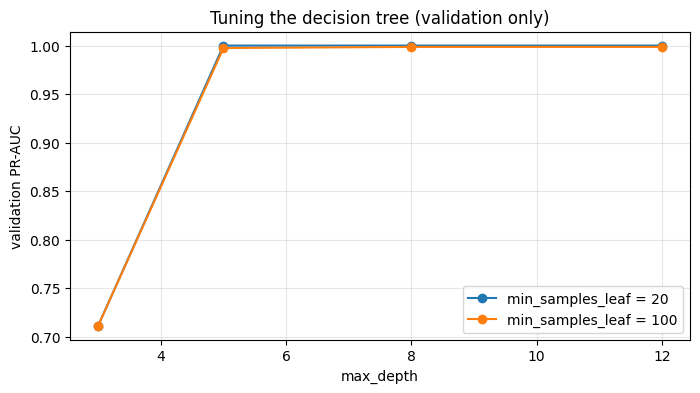

Finding: best settings are {'max_depth': 5, 'min_samples_leaf': 20} with validation PR-AUC 1.0000. The test set was not used.


In [9]:
DEPTHS = [3, 5, 8, 12]
LEAVES = [20, 100]

rows = []
for depth in DEPTHS:
    for leaf in LEAVES:
        p = new_pipeline(DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED))
        p.fit(X_train, y_train)
        s = p.predict_proba(X_val)[:, 1]
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, "val PR-AUC": metrics.pr_auc(y_val, s)})
tuning = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)
display(tuning)

best_row = tuning.iloc[0]
BEST_PARAMS = {"max_depth": int(best_row["max_depth"]), "min_samples_leaf": int(best_row["min_samples_leaf"])}

fig, ax = plt.subplots()
for leaf in LEAVES:
    sel = tuning[tuning["min_samples_leaf"] == leaf].sort_values("max_depth")
    ax.plot(sel["max_depth"], sel["val PR-AUC"], marker="o", label=f"min_samples_leaf = {leaf}")
ax.set_xlabel("max_depth"); ax.set_ylabel("validation PR-AUC"); ax.set_title("Tuning the decision tree (validation only)"); ax.legend()
plt.show()
print(f"Finding: best settings are {BEST_PARAMS} with validation PR-AUC {best_row['val PR-AUC']:.4f}. The test set was not used.")

## 7. Results on the natural-rate test set

### 7.1 Final results table

**Purpose:** Stage 7 (evaluation). This is the first time the **test set** is used. It keeps its natural fraud rate, so the numbers show how the model would behave on real traffic.

**What we did:** fitted the chosen tree (best settings from 6.2) on the sampled training set, then evaluated the dummy and the tree on validation and test with our metrics module. The results table has one row per model and period.

**What each column means (one line each):**
- **PR-AUC:** area under the precision-recall curve (average precision); our main metric, because it focuses on the rare fraud class.
- **ROC-AUC:** area under the ROC curve; shown for reference only, because it looks optimistic when fraud is rare.
- **recall@90%precision:** the share of frauds we catch if we only accept alert levels where at least 90 % of alerts are real fraud (0 means that precision is never reached).
- **precision@0.5:** share of alerts that are real fraud when we flag scores of 0.5 or higher.
- **recall@0.5:** share of all frauds caught at the same 0.5 threshold.
- **alerts:** number of transactions flagged at 0.5; an analyst has to check each one.

**If the tree's PR-AUC is very high:** do not panic and do not hide it. The full feature set contains **post-transaction balances** (`newbalanceOrig`, `newbalanceDest` and values built from them) that a real system would not have *before* approving a payment. This is exactly the **realism gap** that RQ2 studies; the Week 13 ablation on the `deployable` feature set measures it.

**How to read the output:** compare the dummy and tree rows on the test period; the tree should be far above the dummy on PR-AUC.

In [10]:
tree_pipe = new_pipeline(DecisionTreeClassifier(random_state=SEED, **BEST_PARAMS))
tree_pipe.fit(X_train, y_train)

tree_val_scores   = tree_pipe.predict_proba(X_val)[:, 1]
tree_test_scores  = tree_pipe.predict_proba(X_test)[:, 1]
dummy_test_scores = dummy_pipe.predict_proba(X_test)[:, 1]

all_rows = []
for model_name, s_val, s_test in [("Dummy (prior)", dummy_val_scores, dummy_test_scores),
                                  (f"Decision tree (depth {BEST_PARAMS['max_depth']}, leaf {BEST_PARAMS['min_samples_leaf']})", tree_val_scores, tree_test_scores)]:
    all_rows.append({"model": model_name, "period": "validation", **metrics.evaluate(y_val, s_val)})
    all_rows.append({"model": model_name, "period": "test", **metrics.evaluate(y_test, s_test)})
results_all = pd.DataFrame(all_rows)
results_test = results_all[results_all["period"] == "test"].drop(columns="period").reset_index(drop=True)

print("Test set (natural fraud rate):")
display(results_test)
print("Validation set (for comparison):")
display(results_all[results_all["period"] == "validation"].drop(columns="period").reset_index(drop=True))

dummy_test_acc = accuracy_score(y_test, dummy_pipe.predict(X_test))
test_rate = float(y_test.mean())
tree_r = results_test.iloc[1]
print(f"Accuracy trap on test: the dummy is {dummy_test_acc:.2%} accurate with recall {results_test.iloc[0]['recall@0.5']:.0%}.")
print(f"Finding: test fraud rate {test_rate:.3%} (no-skill PR-AUC). Tree PR-AUC = {tree_r['PR-AUC']:.3f}, ROC-AUC = {tree_r['ROC-AUC']:.3f}, "
      f"recall at 90% precision = {tree_r['recall@90%precision']:.3f}, recall at 0.5 = {tree_r['recall@0.5']:.3f} with {int(tree_r['alerts']):,} alerts.")
if tree_r["PR-AUC"] > 0.9:
    print("Note: PR-AUC is very high. This is expected with post-transaction balances in the full feature set (realism gap, RQ2). See the markdown above.")

Test set (natural fraud rate):


,model,PR-AUC,ROC-AUC,recall@90%precision,precision@0.5,recall@0.5,alerts
0,Dummy (prior),0.0367,0.5000,0.0000,0.0000,0.0000,0
1,"Decision tree (depth 5, leaf 20)",1.0000,1.0000,1.0000,0.9994,1.0000,1601


Validation set (for comparison):


,model,PR-AUC,ROC-AUC,recall@90%precision,precision@0.5,recall@0.5,alerts
0,Dummy (prior),0.0130,0.5000,0.0000,0.0000,0.0000,0
1,"Decision tree (depth 5, leaf 20)",1.0000,1.0000,1.0000,1.0000,1.0000,1052


Accuracy trap on test: the dummy is 96.33% accurate with recall 0%.
Finding: test fraud rate 3.674% (no-skill PR-AUC). Tree PR-AUC = 1.000, ROC-AUC = 1.000, recall at 90% precision = 1.000, recall at 0.5 = 1.000 with 1,601 alerts.
Note: PR-AUC is very high. This is expected with post-transaction balances in the full feature set (realism gap, RQ2). See the markdown above.


### 7.2 Precision-recall curves

**Purpose:** a single number hides the trade-off between catching frauds (recall) and raising false alarms (precision). The PR curve shows the whole trade-off.

**What we did:** plotted precision against recall on the **test set** for the dummy and the tree. A dotted horizontal line marks **90 % precision**, and a marker shows where the tree sits at the best recall that still keeps 90 % precision. The grey line is the no-skill level (the test fraud rate).

**How to read the output:** **up and to the right is better.** A curve that stays near the top while recall grows means the model finds many frauds with few false alarms. The dummy collapses to the no-skill line.

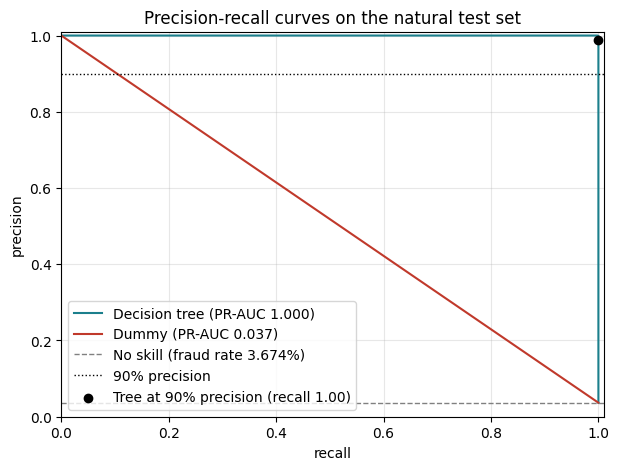

Finding: at 90% precision the tree catches 100.0% of the frauds in the test period.


In [11]:
p_d, r_d, _ = precision_recall_curve(y_test, dummy_test_scores)
p_t, r_t, _ = precision_recall_curve(y_test, tree_test_scores)
r90, thr90 = metrics.recall_at_precision(y_test, tree_test_scores, 0.90)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(r_t, p_t, color="#1B7F8C", label=f"Decision tree (PR-AUC {results_test.iloc[1]['PR-AUC']:.3f})")
ax.plot(r_d, p_d, color="#C0392B", label=f"Dummy (PR-AUC {results_test.iloc[0]['PR-AUC']:.3f})")
ax.axhline(test_rate, color="grey", linestyle="--", linewidth=1, label=f"No skill (fraud rate {test_rate:.3%})")
ax.axhline(0.90, color="black", linestyle=":", linewidth=1, label="90% precision")
if thr90 is not None:
    p90, _, _ = metrics.precision_recall_at_threshold(y_test, tree_test_scores, thr90)
    ax.scatter([r90], [p90], color="black", zorder=5, label=f"Tree at 90% precision (recall {r90:.2f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.01)
ax.set_title("Precision-recall curves on the natural test set"); ax.legend(loc="lower left")
plt.show()
print(f"Finding: at 90% precision the tree catches {r90:.1%} of the frauds in the test period." if thr90 is not None
      else "Finding: the tree never reaches 90% precision on the test set.")

## 8. Sampling demo: why we never evaluate on sampled data

**Purpose:** show with numbers the "watch out" from the course guide. If the *test* set is sampled in the same way as the training set, the metrics look much better than they really are.

**What we did:** evaluated **the same fitted tree** on (a) the natural test set and (b) a sampled test set (all frauds plus 10 % of normal rows). Nothing was refitted. We compared PR-AUC and precision.

**How to read the output:** the sampled test set looks better, especially on **precision** and **PR-AUC**: removing 90 % of the normal rows removes most false alarms and raises the fraud share, so precision is inflated. Recall is unchanged, because all frauds are still there. That is why we always report results on the natural test set.

,rows,fraud_rate_%,PR-AUC,precision@0.5,recall@0.5
natural test (honest),43550,3.6739,1.0000,0.9994,1.0000
sampled test (inflated),5795,27.6100,1.0000,1.0000,1.0000


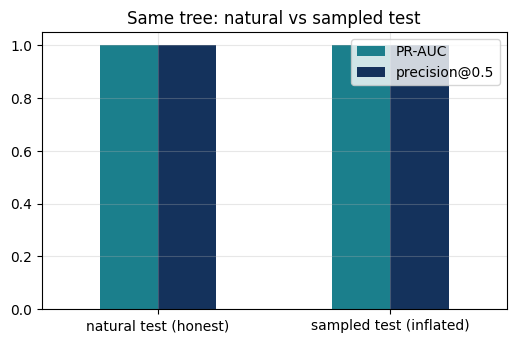

Finding: sampling the test set raises PR-AUC by +0.000 and precision@0.5 by +0.001, while the model is exactly the same. Sampled test results are inflated and must never be reported.


In [12]:
test_sampled = pipeline.sample_training(test, frac_normal=0.10, seed=SEED)
X_test_s, y_test_s = make_xy(test_sampled)
tree_test_s_scores = tree_pipe.predict_proba(X_test_s)[:, 1]

m_nat = metrics.evaluate(y_test, tree_test_scores)
m_smp = metrics.evaluate(y_test_s, tree_test_s_scores)
demo = pd.DataFrame({
    "rows": [len(y_test), len(y_test_s)],
    "fraud_rate_%": [100 * y_test.mean(), 100 * y_test_s.mean()],
    "PR-AUC": [m_nat["PR-AUC"], m_smp["PR-AUC"]],
    "precision@0.5": [m_nat["precision@0.5"], m_smp["precision@0.5"]],
    "recall@0.5": [m_nat["recall@0.5"], m_smp["recall@0.5"]],
}, index=["natural test (honest)", "sampled test (inflated)"])
display(demo)

fig, ax = plt.subplots(figsize=(6, 3.6))
demo[["PR-AUC", "precision@0.5"]].plot.bar(ax=ax, color=["#1B7F8C", "#14325C"]); ax.set_ylim(0, 1.05)
ax.set_title("Same tree: natural vs sampled test"); plt.xticks(rotation=0); plt.show()

SAMPLING_PRAUC_GAIN = float(m_smp["PR-AUC"] - m_nat["PR-AUC"])
SAMPLING_PREC_GAIN  = float(m_smp["precision@0.5"] - m_nat["precision@0.5"])
print(f"Finding: sampling the test set raises PR-AUC by {SAMPLING_PRAUC_GAIN:+.3f} and precision@0.5 by {SAMPLING_PREC_GAIN:+.3f}, "
      f"while the model is exactly the same. Sampled test results are inflated and must never be reported.")

## 9. Save outputs

**Purpose:** teammates should not repeat our work. Salman's app page (`app/pages/2_Baseline_Model.py`) reads the results file and loads the saved model, and the final demo reuses them.

**What we did:** saved three small files:
- **`baseline_decision_tree.joblib`**: the fitted Pipeline (encoder, scaler and tree in one object). It goes to `models/` in the repo.
- **`baseline_results.csv`**: the test-set results table (dummy vs tree). It goes to `app/data/` in the repo.
- **`baseline_info.json`**: the feature list, the chosen parameters, the cut-offs, the sampling rate and the scikit-learn version, so anyone can reproduce or audit the run.

We copied them to a Drive output folder and started the download to your computer.

**How to read the output:** a list of files with sizes. The model file should be small (under a few MB). Do **not** commit data files (`.parquet`, `.csv.gz`); only these three outputs go to git.

In [19]:

OUT_LOCAL = "/content/outputs_week8"
OUT_DRIVE = PROC_DIR
os.makedirs(OUT_LOCAL, exist_ok=True)
os.makedirs(OUT_DRIVE, exist_ok=True)

model_path   = OUT_LOCAL + "/baseline_decision_tree.joblib"
results_path = OUT_LOCAL + "/baseline_results.csv"
info_path    = OUT_LOCAL + "/baseline_info.json"

joblib.dump(tree_pipe, model_path, compress=3)
results_test.to_csv(results_path, index=False)

info = {
    "week": 8,
    "seed": SEED,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "python_version": platform.python_version(),
    "features_full": FULL_FEATURES,
    "features_categorical": CAT_COLS,
    "features_numeric_scaled": NUM_COLS,
    "features_flags": FLAG_COLS,
    "chosen_parameters": BEST_PARAMS,
    "cutoffs": {"train_step_max": int(TRAIN_END), "validation_step_max": int(VAL_END), "test_step_min_exclusive": int(VAL_END)},
    "training_sampling": {"frauds_kept": "all", "normal_fraction": 0.10, "seed": SEED, "training_fraud_rate": float(y_train.mean())},
    "natural_test_fraud_rate": float(y_test.mean()),
    "validation_pr_auc_of_chosen_tree": float(best_row["val PR-AUC"]),
    "test_metrics_tree": {k: float(v) for k, v in results_test.iloc[1].items() if k != "model"},
    "test_metrics_dummy": {k: float(v) for k, v in results_test.iloc[0].items() if k != "model"},
    "note": "Probabilities are not calibrated (training set was sampled). Use PR-AUC, not accuracy."
}

with open(info_path, "w") as f:
    json.dump(info, f, indent=2)

# Save all three files directly to Google Drive/processed
for p in (model_path, results_path, info_path):
    drive_path = os.path.join(OUT_DRIVE, os.path.basename(p))
    subprocess.run(["cp", p, drive_path], check=True)

print("Saved locally and to Drive:", OUT_DRIVE)

for f_ in sorted(os.listdir(OUT_LOCAL)):
    print(f" - {f_} ({os.path.getsize(os.path.join(OUT_LOCAL, f_)) / 1e6:.3f} MB)")

model_mb = os.path.getsize(model_path) / 1e6
print(f"Finding: the model file is {model_mb:.2f} MB" + (" (small enough to commit)." if model_mb < 10 else " (large: reduce max_depth or check what was saved)."))

# Reload test: saved Pipeline must give identical scores
check = joblib.load(model_path).predict_proba(X_test.head(2000))[:, 1]
assert np.allclose(check, tree_pipe.predict_proba(X_test.head(2000))[:, 1]), "Saved model differs from the fitted model"
print("Reload check passed: identical prediction scores.")

# Verify all three files exist in Google Drive/processed
for p in (model_path, results_path, info_path):
    drive_path = os.path.join(OUT_DRIVE, os.path.basename(p))
    assert os.path.exists(drive_path), f"File missing from Drive: {drive_path}"

print("Drive verification passed: all three files are saved in processed.")


Saved locally and to Drive: /content/drive/MyDrive/DS311_P12_Data/processed
 - baseline_decision_tree.joblib (0.004 MB)
 - baseline_info.json (0.002 MB)
 - baseline_results.csv (0.000 MB)
Finding: the model file is 0.00 MB (small enough to commit).
Reload check passed: identical prediction scores.
Drive verification passed: all three files are saved in processed.


## 10. Summary and next steps

**Purpose:** Stage 8 (interpretation). The code cell below prints the key findings **from variables** (nothing typed by hand), so the numbers always match the run. The markdown cell after it states the limits of this work and what comes next.

**How to read the output:** one block of lines, in the order of the notebook: data, split, sampling, tuning, test results, accuracy trap, sampling demo.

In [14]:
t = results_test.iloc[1]
d = results_test.iloc[0]
print("SUMMARY OF WEEK 8 (all numbers come from this run)")
print("-" * 70)
print(f"Data: {len(df):,} rows (TRANSFER and CASH_OUT), {int(df['isFraud'].sum()):,} frauds ({df['isFraud'].mean():.3%}).")
print(f"Split by time: train <= {TRAIN_END} ({len(train):,} rows, {int(train['isFraud'].sum()):,} frauds), "
      f"validation {TRAIN_END + 1}-{VAL_END} ({len(val):,}, {int(val['isFraud'].sum()):,}), test > {VAL_END} ({len(test):,}, {int(test['isFraud'].sum()):,}).")
print(f"Training sampled to {len(train_s):,} rows ({y_train.mean():.2%} fraud); validation and test kept at the natural rate.")
print(f"Model inputs: {len(FULL_FEATURES)} features (full set, includes post-transaction balances).")
print(f"Best tree on validation: {BEST_PARAMS} (validation PR-AUC {best_row['val PR-AUC']:.4f}).")
print(f"Test, dummy: PR-AUC {d['PR-AUC']:.4f}, recall@0.5 {d['recall@0.5']:.0%}, accuracy {dummy_test_acc:.2%}.")
print(f"Test, tree : PR-AUC {t['PR-AUC']:.4f}, ROC-AUC {t['ROC-AUC']:.4f}, recall@90%precision {t['recall@90%precision']:.3f}, "
      f"precision@0.5 {t['precision@0.5']:.3f}, recall@0.5 {t['recall@0.5']:.3f}, alerts {int(t['alerts']):,}.")
print(f"Tree beats the no-skill level ({test_rate:.4f}) by a factor of {t['PR-AUC'] / test_rate:,.0f} on PR-AUC.")
print(f"Sampling the test set would inflate PR-AUC by {SAMPLING_PRAUC_GAIN:+.3f} and precision by {SAMPLING_PREC_GAIN:+.3f}.")
print(f"Saved: model ({model_mb:.2f} MB), results CSV, info JSON; scikit-learn {sklearn.__version__} pinned for the app.")

SUMMARY OF WEEK 8 (all numbers come from this run)
----------------------------------------------------------------------
Data: 2,770,409 rows (TRANSFER and CASH_OUT), 8,213 frauds (0.296%).
Split by time: train <= 500 (2,645,779 rows, 5,561 frauds), validation 501-600 (81,080, 1,052), test > 600 (43,550, 1,600).
Training sampled to 269,583 rows (2.06% fraud); validation and test kept at the natural rate.
Model inputs: 14 features (full set, includes post-transaction balances).
Best tree on validation: {'max_depth': 5, 'min_samples_leaf': 20} (validation PR-AUC 1.0000).
Test, dummy: PR-AUC 0.0367, recall@0.5 0%, accuracy 96.33%.
Test, tree : PR-AUC 1.0000, ROC-AUC 1.0000, recall@90%precision 1.000, precision@0.5 0.999, recall@0.5 1.000, alerts 1,601.
Tree beats the no-skill level (0.0367) by a factor of 27 on PR-AUC.
Sampling the test set would inflate PR-AUC by +0.000 and precision by +0.001.
Saved: model (0.00 MB), results CSV, info JSON; scikit-learn 1.6.1 pinned for the app.


### Limitations

- **Synthetic data.** PaySim is a simulation, so real fraud may behave differently (new tactics, other regions, other channels).
- **Post-transaction features.** The full feature set contains balances recorded *after* the transaction. A live system would not have them at approval time, so these results are probably optimistic. Week 13 compares the `full` and `deployable` feature sets to measure this realism gap (RQ2).
- **Uncalibrated 0.5 threshold.** The training set was sampled, so predicted probabilities are inflated. The 0.5 threshold is a convention, not a decision tuned to the cost of a missed fraud versus a false alarm.
- **One time split, one seed.** Results come from a single split and seed; a different cut-off or seed may change the numbers slightly.
- **Trees only.** A single decision tree is a first baseline, not our final model.
